# ♻️ Residuo Cero · Entrenamiento del clasificador de residuos
### IA Generativa para la Gestión Industrial · Certamen: app web con modelos preentrenados
**Integrantes:** Felipe Alonso · Sofía Fariña · Vicente Lagunas

**Objetivo:** clasificar la foto de un residuo en 6 clases (cartón, vidrio, metal, papel, plástico, basura) con un modelo preentrenado, compararlo con una línea base y exportarlo para la app.

📷 Foto → 🧠 Modelo preentrenado → 📊 Clase + confianza → 💬 LLM → ✅ Recomendación

**Antes de empezar:** en Colab ve a *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

## 0. Librerías

In [1]:
!pip install -q timm datasets transformers scikit-learn

import os, json, hashlib, random                 # utilidades generales
import numpy as np                               # cálculo con matrices
import matplotlib.pyplot as plt                  # gráficos
import torch, torch.nn as nn                     # PyTorch: motor de deep learning
from torch.utils.data import Dataset, DataLoader # para alimentar el modelo por lotes
from torchvision import transforms               # transformaciones de imagen
import timm                                      # modelos de visión preentrenados
from datasets import load_dataset                # descarga datasets de Hugging Face
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, balanced_accuracy_score)
import warnings; warnings.filterwarnings("ignore")

SEMILLA = 1993                                     # semilla fija: resultados reproducibles
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


## 1. Los datos

| Aspecto | Detalle |
|---|---|
| Dataset | **TrashNet** |
| Autores | Gary Thung y Mindy Yang (Universidad de Stanford, 2016) |
| Cómo se obtuvo | Fotos tomadas a mano de residuos sobre un fondo blanco o gris, con luz natural y de sala |
| Licencia | **MIT** |
| Copia usada | Hugging Face: `garythung/trashnet`, archivo `dataset-resized.zip` (2.527 fotos, una carpeta por clase) |
| Clases | `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash` (TrashNet) y `other` (objetos que no son residuos, ver 1.0) |

**Nota:** El repositorio de Hugging Face contiene la versión original y la redimensionada de las mismas fotos. Cargarlo completo cuenta cada foto dos veces (5.054 filas) y filtraría imágenes entre train y test; por eso se usa solo `dataset-resized.zip`.

**Referencias:** Yang, M. y Thung, G. (2016). *Classification of Trash for Recyclability Status*. Stanford CS229. · https://huggingface.co/datasets/garythung/trashnet · https://github.com/garythung/trashnet

In [2]:
from huggingface_hub import hf_hub_download
import zipfile

# el repositorio trae dos zips (original y resized) con las MISMAS fotos; usamos solo la versión redimensionada
zip_ruta = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")
with zipfile.ZipFile(zip_ruta) as z:                      # descomprime en la carpeta "trashnet"
    z.extractall("trashnet")

CLASES_ESPERADAS = {"cardboard", "glass", "metal", "paper", "plastic", "trash"}
RAIZ_DATOS = next(r for r, d, _ in os.walk("trashnet")    # busca la carpeta que contiene las 6 carpetas de clase
                  if "__MACOSX" not in r and CLASES_ESPERADAS <= set(d))
print("Carpeta de datos:", RAIZ_DATOS)

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Carpeta de datos: trashnet/dataset-resized


### 1.0 La clase «other» (objetos que no son residuos)
Con solo las 6 clases de TrashNet el modelo **siempre** elige un material: un zapato salía como `glass` con 92 % de confianza, porque no tiene dónde ponerlo. Agregamos una séptima clase, **`other`**, con fotos de cosas que no son residuos reciclables (calzado, ropa, bolsos, electrónicos, muebles, juguetes, vehículos, paisajes).

Fuentes (ambas públicas en Hugging Face):
- **ImageNet-1k** (versión 256x256, split de validación): fotos de objetos cotidianos en escenas naturales.
- **Fashion Products** (`ceyda/fashion-products-small`): fotos de calzado, ropa y accesorios **sobre fondo blanco**. Sirven para que el modelo no aprenda el atajo «fondo liso = residuo», ya que TrashNet tiene fondos lisos.

Se excluyeron a propósito las clases que se parecen a residuos (botellas, latas, cartones, bolsas, libros, tazas, tarros).

Se reservan dos grupos que **no** entran a train, val ni test, para probar de verdad el problema original:
- `zapatos_prueba/`: zapatos nunca vistos.
- `otro_nunca_visto/`: categorías de objetos que el modelo no vio en ningún momento (pizza, castillo, tractor…).

In [5]:
import shutil
from PIL import Image

POR_CLASE_IN = 4                 # fotos por cada clase de ImageNet elegida
N_CALZADO, N_MODA = 90, 110      # fotos de producto con fondo blanco que entran a «other»
N_ZAPATOS_PRUEBA, N_NUNCA_POR_CLASE = 30, 5
CARPETA_OTHER = os.path.join(RAIZ_DATOS, "other")
CARPETA_ZAPATOS, CARPETA_NUNCA = "zapatos_prueba", "otro_nunca_visto"
for c in (CARPETA_OTHER, CARPETA_ZAPATOS, CARPETA_NUNCA):          # limpia si se vuelve a ejecutar
    shutil.rmtree(c, ignore_errors=True); os.makedirs(c)
rng = np.random.RandomState(SEMILLA)

# ---- (a) ImageNet: solo las clases elegidas, sin nada que se parezca a un residuo
CLASES_IN = ["running shoe", "sandal", "loafer", "clog", "cowboy boot", "sock", "sweatshirt", "jersey", "jean",
             "cowboy hat", "umbrella", "backpack", "purse", "wallet", "sunglasses", "laptop", "cellular telephone",
             "mouse", "remote control", "computer keyboard", "monitor", "television", "ipod", "digital watch",
             "barber chair", "folding chair", "rocking chair", "studio couch", "desk", "dining table", "table lamp",
             "pillow", "park bench", "golden retriever", "tabby", "egyptian cat", "zebra", "indian elephant",
             "teddy", "acoustic guitar", "electric guitar", "violin", "hammer", "screwdriver", "sports car",
             "mountain bike", "volcano", "valley", "cliff", "coral reef"]
CLASES_NUNCA = ["pizza", "castle", "tractor", "lion", "microwave", "refrigerator", "washer", "vacuum"]

# data_files: baja SOLO los 2 archivos de validación (~670 MB). Sin esto, load_dataset baja también train y test (~17 GB)
imnet = load_dataset("benjamin-paine/imagenet-1k-256x256",
                     data_files={"validation": "data/validation-*.parquet"}, split="validation",
                     verification_mode="no_checks")
primer_nombre = [n.split(",")[0].strip().lower() for n in imnet.features["label"].names]
assert len(primer_nombre) >= 1000, len(primer_nombre)

etq_in = np.array(imnet["label"])                                                    # solo lee la columna de etiquetas

def guardar_imagenet(nombres, por_clase, carpeta, prefijo):
    total = 0
    for nombre in nombres:
        k = primer_nombre.index(nombre)
        for j in rng.choice(np.where(etq_in == k)[0], por_clase, replace=False):
            imnet[int(j)]["image"].convert("RGB").save(f"{carpeta}/{prefijo}_{k}_{j}.jpg", quality=92)
            total += 1
    return total

n_in = guardar_imagenet(CLASES_IN, POR_CLASE_IN, CARPETA_OTHER, "in")
n_nunca = guardar_imagenet(CLASES_NUNCA, N_NUNCA_POR_CLASE, CARPETA_NUNCA, "nunca")
del imnet

# ---- (b) Fashion Products: fotos de producto con fondo blanco
moda = load_dataset("ceyda/fashion-products-small", split="train")
master, sub = np.array(moda["masterCategory"]), np.array(moda["subCategory"])
print("masterCategory:", sorted(set(master)))
print("subCategory:", sorted(set(sub)))

CATEGORIAS_MODA = {"Topwear", "Bottomwear", "Bags", "Watches", "Eyewear", "Wallets", "Belts", "Headwear", "Socks"}
i_calzado = rng.permutation(np.where(master == "Footwear")[0])
i_moda = rng.permutation(np.where(np.isin(sub, list(CATEGORIAS_MODA)))[0])

def guardar_moda(indices, carpeta, prefijo):
    for j in indices:
        moda[int(j)]["image"].convert("RGB").save(f"{carpeta}/{prefijo}_{j}.jpg", quality=92)

guardar_moda(i_calzado[:N_CALZADO], CARPETA_OTHER, "calzado")
guardar_moda(i_moda[:N_MODA], CARPETA_OTHER, "moda")
guardar_moda(i_calzado[N_CALZADO:N_CALZADO + N_ZAPATOS_PRUEBA], CARPETA_ZAPATOS, "zapato")   # reservados, nunca se entrena con ellos
del moda

print(f"«other»: {len(os.listdir(CARPETA_OTHER))} fotos · zapatos reservados: {len(os.listdir(CARPETA_ZAPATOS))} · "
      f"categorías nunca vistas: {len(os.listdir(CARPETA_NUNCA))}")

README.md:   0%|          | 0.00/151 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.63k [00:00<?, ?B/s]

data/train-00000-of-00002-357f4cbabe1a8e(…): reconstructing file:   0%|          |  0.00B /  298MB            

data/train-00000-of-00002-357f4cbabe1a8e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cbe936f1880f5e(…): reconstructing file:   0%|          |  0.00B /  299MB            

data/train-00001-of-00002-cbe936f1880f5e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/42700 [00:00<?, ? examples/s]

masterCategory: [np.str_('Accessories'), np.str_('Apparel'), np.str_('Footwear'), np.str_('Free Items'), np.str_('Home'), np.str_('Personal Care'), np.str_('Sporting Goods')]
subCategory: [np.str_('Accessories'), np.str_('Apparel Set'), np.str_('Bags'), np.str_('Bath and Body'), np.str_('Beauty Accessories'), np.str_('Belts'), np.str_('Bottomwear'), np.str_('Cufflinks'), np.str_('Dress'), np.str_('Eyes'), np.str_('Eyewear'), np.str_('Flip Flops'), np.str_('Fragrance'), np.str_('Free Gifts'), np.str_('Gloves'), np.str_('Hair'), np.str_('Headwear'), np.str_('Home Furnishing'), np.str_('Innerwear'), np.str_('Jewellery'), np.str_('Lips'), np.str_('Loungewear and Nightwear'), np.str_('Makeup'), np.str_('Mufflers'), np.str_('Nails'), np.str_('Perfumes'), np.str_('Sandal'), np.str_('Saree'), np.str_('Scarves'), np.str_('Shoe Accessories'), np.str_('Shoes'), np.str_('Skin'), np.str_('Skin Care'), np.str_('Socks'), np.str_('Sports Accessories'), np.str_('Sports Equipment'), np.str_('Stoles'), n

In [6]:
assert CLASES_ESPERADAS | {"other"} <= set(os.listdir(RAIZ_DATOS))
ds = load_dataset("imagefolder", data_dir=RAIZ_DATOS, split="train")   # el nombre de cada carpeta es la etiqueta
NOMBRES = ds.features["label"].names                      # nombres de las clases (orden alfabético)
print(ds)
print("Clases:", NOMBRES)

Resolving data files:   0%|          | 0/2927 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 2927
})
Clases: ['cardboard', 'glass', 'metal', 'other', 'paper', 'plastic', 'trash']


### 1.1 Imágenes por clase y desbalance

cardboard :   403  (13.8%)
glass     :   501  (17.1%)
metal     :   410  (14.0%)
other     :   400  (13.7%)
paper     :   594  (20.3%)
plastic   :   482  (16.5%)
trash     :   137  (4.7%)
Razón mayor / menor clase: 4.3


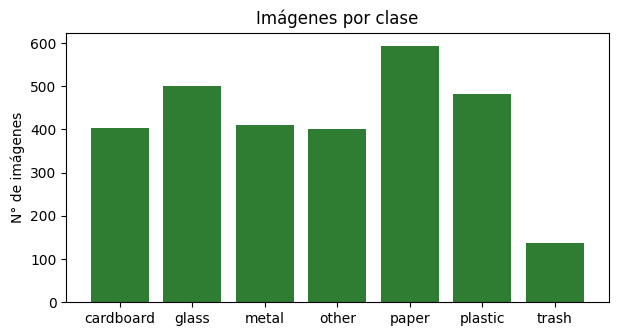

In [7]:
etiquetas = np.array(ds["label"])                         # etiqueta de cada imagen
conteo = np.bincount(etiquetas, minlength=len(NOMBRES))   # cuántas imágenes tiene cada clase

for n, c in zip(NOMBRES, conteo):
    print(f"{n:10s}: {c:5d}  ({c / conteo.sum():.1%})")
print("Razón mayor / menor clase:", round(conteo.max() / conteo.min(), 1))

plt.figure(figsize=(7, 3.5))
plt.bar(NOMBRES, conteo, color="#2e7d32")
plt.title("Imágenes por clase"); plt.ylabel("N° de imágenes"); plt.show()

### 1.2 Ejemplos de cada clase

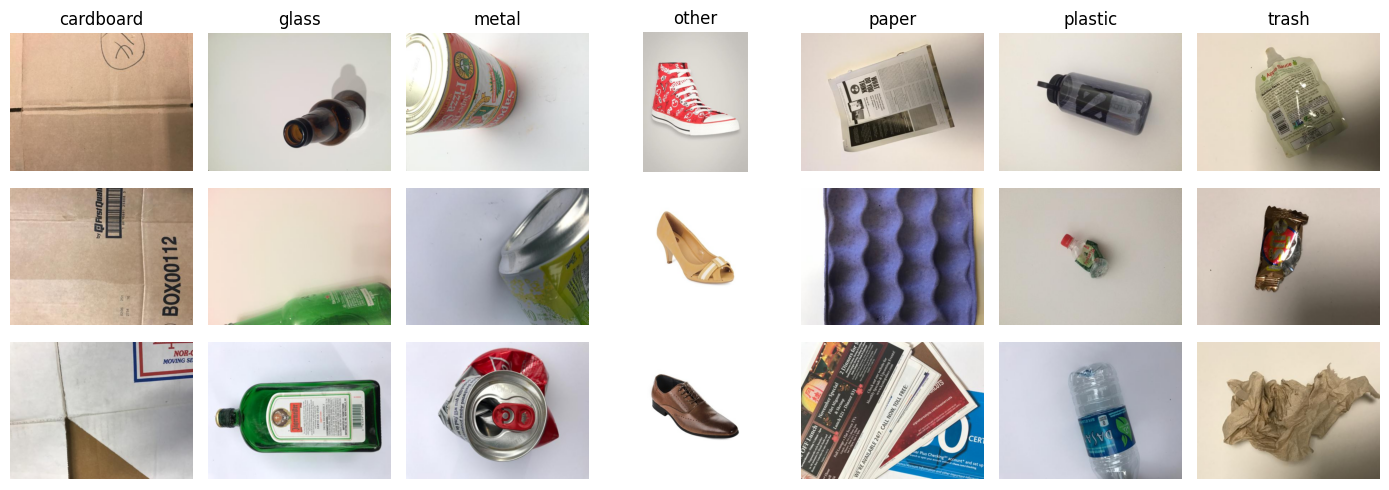

In [9]:
plt.figure(figsize=(14, 5))
for k, n in enumerate(NOMBRES):
    idx = np.where(etiquetas == k)[0][:3]                 # 3 fotos de la clase
    for j, i in enumerate(idx):
        plt.subplot(3, len(NOMBRES), j * len(NOMBRES) + k + 1)

        plt.imshow(ds[int(i)]["image"]); plt.axis("off")
        if j == 0: plt.title(n)
plt.tight_layout(); plt.show()

### 1.3 Duplicados exactos y división train / val / test
Si una misma foto cae en *train* y en *test*, el modelo "la recuerda" y la métrica sale inflada (**fuga de datos**). Verificamos que no haya copias exactas antes de dividir: se eliminaron 3, quedando 2.524 imágenes (1.766 train, 379 val y 379 test).


In [10]:
def huella(img):                                           # resumen único del contenido de la foto
    return hashlib.md5(img.convert("RGB").tobytes()).hexdigest()

vistos, unicos = set(), []
for i in range(len(ds)):
    h = huella(ds[i]["image"])
    if h not in vistos:                                    # solo conserva la primera copia
        vistos.add(h); unicos.append(i)
unicos = np.array(unicos)
print(f"Imágenes: {len(ds)} · duplicados exactos eliminados: {len(ds) - len(unicos)} · quedan: {len(unicos)}")

Imágenes: 2927 · duplicados exactos eliminados: 3 · quedan: 2924


In [11]:
y = etiquetas[unicos]                                      # etiquetas de las imágenes únicas
# 70 % train · 15 % val · 15 % test, manteniendo la proporción de cada clase (estratificado)
idx_train, idx_resto = train_test_split(unicos, test_size=0.30, stratify=y, random_state=SEMILLA)
idx_val, idx_test = train_test_split(idx_resto, test_size=0.50, stratify=etiquetas[idx_resto], random_state=SEMILLA)

print(f"{'clase':10s} {'train':>6s} {'val':>6s} {'test':>6s}")
for k, n in enumerate(NOMBRES):
    print(f"{n:10s} {(etiquetas[idx_train]==k).sum():6d} {(etiquetas[idx_val]==k).sum():6d} {(etiquetas[idx_test]==k).sum():6d}")
print(f"{'TOTAL':10s} {len(idx_train):6d} {len(idx_val):6d} {len(idx_test):6d}")

clase       train    val   test
cardboard     282     61     60
glass         350     75     76
metal         286     62     61
other         280     60     60
paper         416     89     89
plastic       336     72     72
trash          96     20     21
TOTAL        2046    439    439


**✏️ Limitaciones de los datos (para la ficha y la exposición):**
- **Una sola fuente para los residuos y un entorno controlado:** las fotos de las 6 clases de TrashNet tienen fondo liso; en la vida real habrá fondos complejos, objetos sucios, aplastados o varios a la vez.
- **Desbalance:** la clase `trash` tiene solo 137 imágenes (4,7 % del total de 2.927) frente a 594 de `paper`.
- **Muy pocas imágenes de `trash` en test:** solo 21, por lo que su recall (85,7 %) tiene mucha incertidumbre: una sola foto cambia el valor en casi 5 puntos.
- **Posibles casi-duplicados:** solo eliminamos 3 copias exactas; fotos casi iguales del mismo objeto podrían seguir repartidas entre train y test.
- **Sin diversidad geográfica:** los envases corresponden a productos de EE. UU., distintos a los chilenos.
- **Clase `other` armada con fuentes distintas:** sus 400 fotos vienen de ImageNet (escenas naturales) y de un catálogo de moda (fondo blanco), no de TrashNet. Se mezclaron ambas para que el modelo no use el tipo de fondo como atajo, pero igual puede haber diferencias de estilo entre `other` y los residuos. Los 30 zapatos y las 40 fotos de categorías de prueba se reservaron fuera de train, val y test.
- **El test de `other` es más fácil que la vida real:** sus fotos salen de las mismas fuentes que las de entrenamiento. Por eso se agregó la prueba 6.3 con categorías que el modelo nunca vio.

## 2. Preparar los datos para PyTorch
Cada foto se redimensiona a 224×224 y se normaliza con las estadísticas de ImageNet (los modelos preentrenados lo esperan así). En *train* agregamos **aumento de datos** (voltear, rotar, variar color).

In [12]:
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # estadísticas de ImageNet
TAM = 224

tf_train = transforms.Compose([
    transforms.RandomResizedCrop(TAM, scale=(0.7, 1.0)),      # recorte aleatorio
    transforms.RandomHorizontalFlip(),                        # volteo horizontal
    transforms.RandomRotation(15),                            # rotación leve
    transforms.ColorJitter(0.2, 0.2, 0.2),                    # brillo, contraste, saturación
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
tf_eval = transforms.Compose([                                # sin azar en val ni test
    transforms.Resize((TAM, TAM)),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])

class Residuos(Dataset):
    def __init__(self, indices, tf):
        self.indices, self.tf = indices, tf
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, k):
        fila = ds[int(self.indices[k])]
        return self.tf(fila["image"].convert("RGB")), fila["label"]

LOTE = 32
dl_train = DataLoader(Residuos(idx_train, tf_train), batch_size=LOTE, shuffle=True, num_workers=2)
dl_val = DataLoader(Residuos(idx_val, tf_eval), batch_size=LOTE, num_workers=2)
dl_test = DataLoader(Residuos(idx_test, tf_eval), batch_size=LOTE, num_workers=2)

## 3. Evaluación común
Para comparar en igualdad de condiciones, **todos los modelos se miden con las mismas imágenes de prueba y con la misma métrica**: *accuracy* y *accuracy balanceada* (promedio del acierto de cada clase; al azar ≈ 17 %). La balanceada importa porque `trash` es una clase escasa.

In [13]:
y_test = etiquetas[idx_test]                                  # etiquetas reales del test

def evaluar(pred, nombre):
    acc = accuracy_score(y_test, pred)
    bal = balanced_accuracy_score(y_test, pred)
    print(f"{nombre}: accuracy = {acc:.3f} · accuracy balanceada = {bal:.3f}")
    return acc, bal

## 4. Línea base · CLIP sin entrenar (zero-shot)
CLIP compara la imagen con una frase por cada clase y elige la más parecida. **No usa ninguna de nuestras etiquetas para aprender**: es el punto de referencia mínimo.

In [14]:
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DISPOSITIVO).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

frases = ["a photo of cardboard waste", "a photo of glass waste", "a photo of metal waste",
          "a photo of an everyday object that is not waste",
          "a photo of paper waste", "a photo of plastic waste", "a photo of general trash"]
assert [n for n in NOMBRES] == ["cardboard", "glass", "metal", "other", "paper", "plastic", "trash"], NOMBRES

pred_clip = []
with torch.no_grad():
    for i in range(0, len(idx_test), 32):
        fotos = [ds[int(j)]["image"].convert("RGB") for j in idx_test[i:i + 32]]
        entrada = proc(text=frases, images=fotos, return_tensors="pt", padding=True).to(DISPOSITIVO)
        pred_clip += clip(**entrada).logits_per_image.argmax(dim=1).cpu().tolist()
pred_clip = np.array(pred_clip)

acc_clip, bal_clip = evaluar(pred_clip, "CLIP zero-shot")
del clip; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot: accuracy = 0.508 · accuracy balanceada = 0.464


## 5. Modelo principal · EfficientNet-B0 con *transfer learning* (timm)
Cargamos EfficientNet-B0 preentrenada en ImageNet, **cambiamos su salida a 6 clases** y la ajustamos con nuestras fotos con una tasa de aprendizaje pequeña (para no "olvidar" lo que ya sabe). Como `trash` es escasa, usamos una **pérdida ponderada por clase**.

In [15]:
modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(NOMBRES)).to(DISPOSITIVO)

pesos = torch.tensor(len(idx_train) / (len(NOMBRES) * np.bincount(etiquetas[idx_train])), dtype=torch.float32)
print("Peso por clase:", dict(zip(NOMBRES, pesos.numpy().round(2))))      # más peso a la clase escasa

perdida = nn.CrossEntropyLoss(weight=pesos.to(DISPOSITIVO))
optim = torch.optim.AdamW(modelo.parameters(), lr=1e-4)                    # tasa de aprendizaje pequeña

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Peso por clase: {'cardboard': np.float32(1.04), 'glass': np.float32(0.84), 'metal': np.float32(1.02), 'other': np.float32(1.04), 'paper': np.float32(0.7), 'plastic': np.float32(0.87), 'trash': np.float32(3.04)}


In [16]:
def predecir(dl):
    modelo.eval(); todas = []
    with torch.no_grad():
        for x, _ in dl:
            todas.append(torch.softmax(modelo(x.to(DISPOSITIVO)), dim=1).cpu())
    return torch.cat(todas).numpy()                                         # probabilidades por clase

EPOCAS, PACIENCIA = 8, 3
y_val = etiquetas[idx_val]
historia = {"loss": [], "val_bal": []}
mejor, sin_mejora = 0, 0

for ep in range(EPOCAS):
    modelo.train(); acumulada = 0
    for x, y_lote in dl_train:
        x, y_lote = x.to(DISPOSITIVO), y_lote.to(DISPOSITIVO)
        optim.zero_grad()
        l = perdida(modelo(x), y_lote)
        l.backward(); optim.step()
        acumulada += l.item() * len(x)
    val_bal = balanced_accuracy_score(y_val, predecir(dl_val).argmax(1))   # se mide en VALIDACIÓN, no en test
    historia["loss"].append(acumulada / len(idx_train)); historia["val_bal"].append(val_bal)
    print(f"Época {ep+1}/{EPOCAS} · pérdida train {historia['loss'][-1]:.3f} · accuracy balanceada val {val_bal:.3f}")
    if val_bal > mejor:                                                    # guarda el mejor modelo
        mejor, sin_mejora = val_bal, 0
        torch.save(modelo.state_dict(), "mejor.pt")
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print("Parada temprana: la validación dejó de mejorar."); break

modelo.load_state_dict(torch.load("mejor.pt"))                              # vuelve al mejor modelo

Época 1/8 · pérdida train 1.904 · accuracy balanceada val 0.712
Época 2/8 · pérdida train 0.612 · accuracy balanceada val 0.809
Época 3/8 · pérdida train 0.348 · accuracy balanceada val 0.848
Época 4/8 · pérdida train 0.215 · accuracy balanceada val 0.867
Época 5/8 · pérdida train 0.168 · accuracy balanceada val 0.873
Época 6/8 · pérdida train 0.108 · accuracy balanceada val 0.879
Época 7/8 · pérdida train 0.109 · accuracy balanceada val 0.886
Época 8/8 · pérdida train 0.062 · accuracy balanceada val 0.898


<All keys matched successfully>

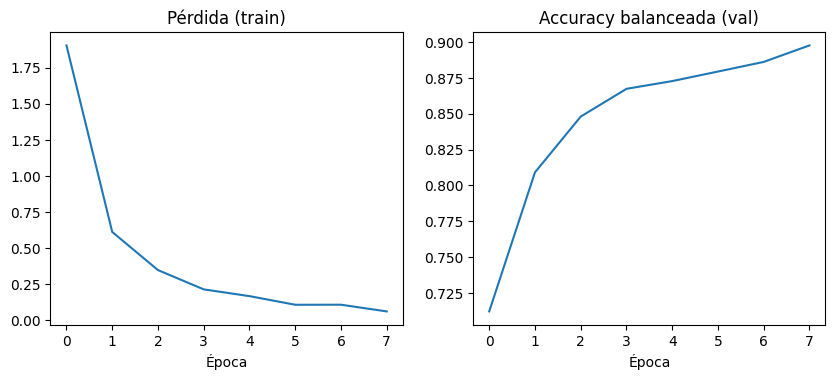

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(historia["loss"]); ax[0].set_title("Pérdida (train)"); ax[0].set_xlabel("Época")
ax[1].plot(historia["val_bal"]); ax[1].set_title("Accuracy balanceada (val)"); ax[1].set_xlabel("Época")
plt.show()

**✏️ ¿Hay overfitting?** Las 8 épocas se completaron sin que se activara la parada temprana. La pérdida de train baja de forma sostenida (de 1,90 a 0,06) y la accuracy balanceada de validación sube en todas las épocas, de 0,71 a 0,90. No veo señales claras de overfitting. El valor de validación (0,90) es cercano al del test (0,88), lo que apoya que el modelo generaliza. Como la validación seguía mejorando en la última época, con más épocas podría subir un poco más.

## 6. Resultados en el conjunto de **prueba**
Esta es la primera vez que el modelo ve el *test*. Estas cifras son el desempeño real que mostrará la app (distinto de la confianza de cada imagen).

In [18]:
prob_test = predecir(dl_test)
pred_eff = prob_test.argmax(1)

acc_eff, bal_eff = evaluar(pred_eff, "EfficientNet-B0")
acc_clip, bal_clip = evaluar(pred_clip, "CLIP zero-shot (línea base)")
print()
print(classification_report(y_test, pred_eff, target_names=NOMBRES, digits=3))

EfficientNet-B0: accuracy = 0.879 · accuracy balanceada = 0.881
CLIP zero-shot (línea base): accuracy = 0.508 · accuracy balanceada = 0.464

              precision    recall  f1-score   support

   cardboard      0.947     0.900     0.923        60
       glass      0.842     0.842     0.842        76
       metal      0.838     0.934     0.884        61
       other      0.966     0.950     0.958        60
       paper      0.907     0.876     0.891        89
     plastic      0.866     0.806     0.835        72
       trash      0.692     0.857     0.766        21

    accuracy                          0.879       439
   macro avg      0.866     0.881     0.871       439
weighted avg      0.883     0.879     0.880       439



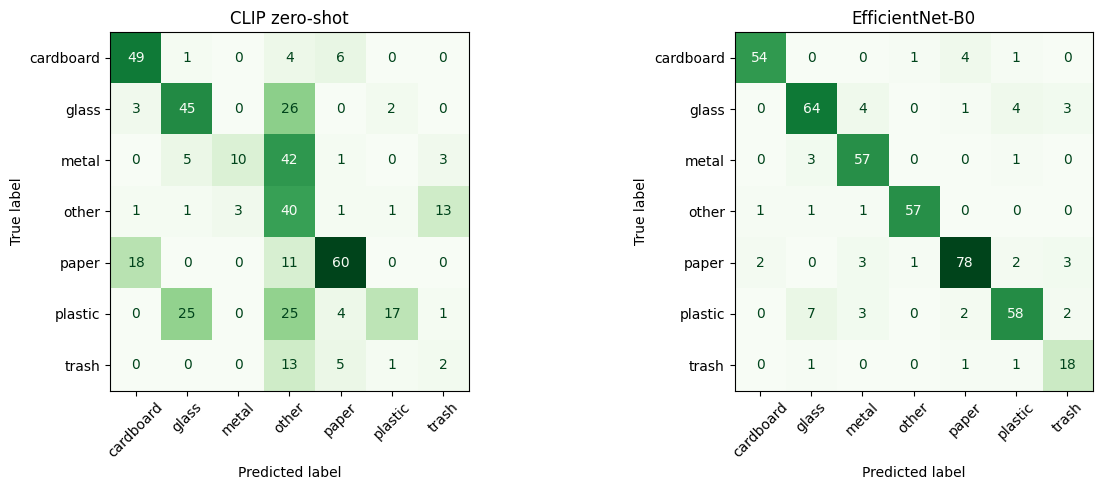

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, pred, titulo in [(ax[0], pred_clip, "CLIP zero-shot"), (ax[1], pred_eff, "EfficientNet-B0")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=NOMBRES).plot(ax=a, cmap="Greens", colorbar=False)
    a.set_title(titulo); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**✏️ Justificación de la elección.** EfficientNet-B0 supera a CLIP sin entrenar en las mismas 439 imágenes de prueba: 87,9 % contra 50,8 % de accuracy, y 88,1 % contra 46,4 % de accuracy balanceada. CLIP no usa nuestras etiquetas, confunde clases parecidas (25 plásticos como vidrio) y manda muchos residuos a `other` (42 de 61 metales y 25 de 72 plásticos); el transfer learning se adapta a los residuos. Además EfficientNet-B0 pesa unos 16 MB, cabe en GitHub y corre en CPU en Streamlit Cloud.

**✏️ Error más costoso.** El más grave es que un residuo no reciclable quede como reciclable, porque contamina el lote completo: ocurrió con 3 de 21 imágenes trash (14,3 %), con un recall de trash de 85,7 %. El error inverso también cuesta, porque se pierde material reciclable: 8 imágenes reciclables se clasificaron como trash (3 vidrio, 3 papel y 2 plástico), y 2 más como `other` (1 cartón y 1 papel). La pérdida ponderada por clase mejora el recall de trash, pero baja su precision (0,69).

In [20]:
cm = confusion_matrix(y_test, pred_eff)
k_trash = NOMBRES.index("trash")
fuga = cm[k_trash].sum() - cm[k_trash, k_trash]
print(f"'trash' clasificada como material reciclable: {fuga} de {cm[k_trash].sum()} ({fuga / cm[k_trash].sum():.1%})")
print(f"Recall de trash: {cm[k_trash, k_trash] / cm[k_trash].sum():.1%}")

'trash' clasificada como material reciclable: 3 de 21 (14.3%)
Recall de trash: 85.7%


### 6.1 ¿Cuándo desconfiar? Confianza de las predicciones

In [21]:
confianza = prob_test.max(1)
correcto = pred_eff == y_test
print(f"Confianza media cuando acierta: {confianza[correcto].mean():.2f} · cuando se equivoca: {confianza[~correcto].mean():.2f}")
for umbral in (0.5, 0.6, 0.7, 0.8, 0.9):
    m = confianza >= umbral
    print(f"Confianza ≥ {umbral:.1f}: {m.mean():.0%} de las fotos · accuracy en ese grupo = {correcto[m].mean():.3f}")

Confianza media cuando acierta: 0.96 · cuando se equivoca: 0.67
Confianza ≥ 0.5: 96% de las fotos · accuracy en ese grupo = 0.905
Confianza ≥ 0.6: 92% de las fotos · accuracy en ese grupo = 0.926
Confianza ≥ 0.7: 89% de las fotos · accuracy en ese grupo = 0.939
Confianza ≥ 0.8: 86% de las fotos · accuracy en ese grupo = 0.953
Confianza ≥ 0.9: 77% de las fotos · accuracy en ese grupo = 0.979


La confianza media es 0,96 cuando el modelo acierta y 0,67 cuando se equivoca, así que sirve para detectar casos dudosos. Con confianza ≥ 0,7 pasa el 89 % de las fotos con 93,9 % de accuracy; el 11 % restante se deriva a revisión humana. Por eso la app usa `UMBRAL_CONFIANZA = 0.70`.

### 6.2 ¿Dónde se equivocó?

Errores: 53 de 439


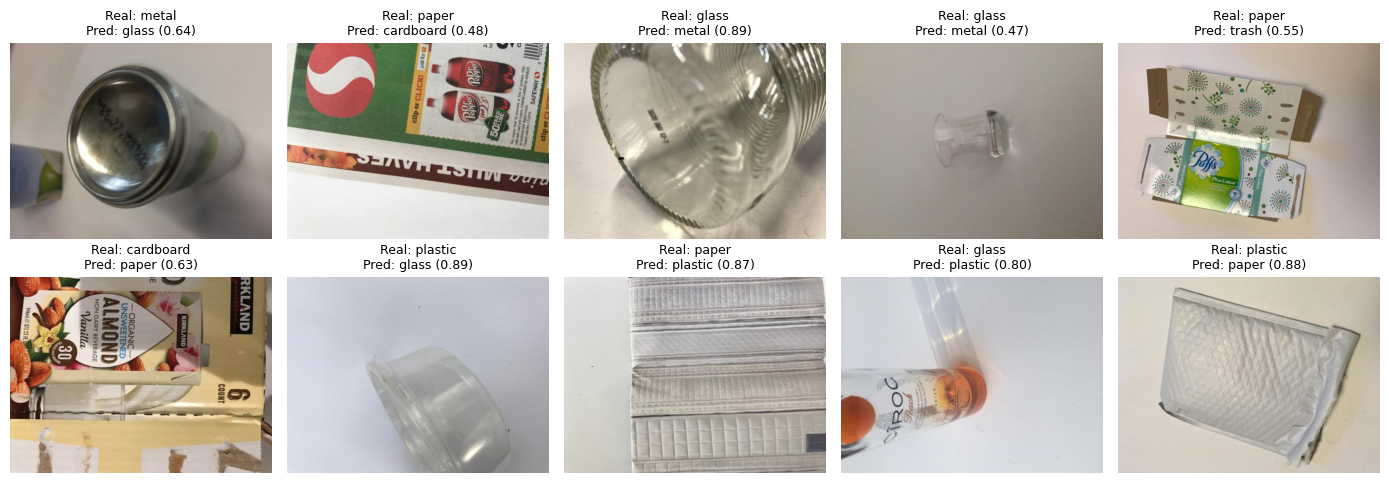

In [22]:
errores = np.where(~correcto)[0]
print("Errores:", len(errores), "de", len(y_test))
plt.figure(figsize=(14, 5))
for k, e in enumerate(errores[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(ds[int(idx_test[e])]["image"]); plt.axis("off")
    plt.title(f"Real: {NOMBRES[y_test[e]]}\nPred: {NOMBRES[pred_eff[e]]} ({confianza[e]:.2f})", fontsize=9)
plt.tight_layout(); plt.show()

### 6.3 El problema original: objetos que no son residuos
Antes, un zapato se clasificaba como `glass` con 92 % de confianza. Aquí se mide con fotos que el modelo **nunca vio**: zapatos reservados y categorías de objetos que no aparecen en el entrenamiento.

In [23]:
k_otro = NOMBRES.index("other")

def predecir_carpeta(carpeta):
    fotos = [Image.open(os.path.join(carpeta, f)).convert("RGB") for f in sorted(os.listdir(carpeta))]
    modelo.eval(); probs = []
    with torch.no_grad():
        for i in range(0, len(fotos), 32):
            x = torch.stack([tf_eval(f) for f in fotos[i:i + 32]]).to(DISPOSITIVO)
            probs.append(torch.softmax(modelo(x), dim=1).cpu())
    return torch.cat(probs).numpy()

# 1) fotos «other» del test: ¿se reconocen?
print(f"Recall de 'other' en test: {cm[k_otro, k_otro] / cm[k_otro].sum():.1%} ({cm[k_otro, k_otro]} de {cm[k_otro].sum()})")

# 2) residuos reales que se marcan como «other»: se perdería material reciclable
falsos_otro = cm[:, k_otro].sum() - cm[k_otro, k_otro]
print(f"Residuos reales clasificados como 'other': {falsos_otro} de {(y_test != k_otro).sum()} ({falsos_otro / (y_test != k_otro).sum():.1%})")

# 3) zapatos y categorías NUNCA vistas
p_zap, p_nv = predecir_carpeta(CARPETA_ZAPATOS), predecir_carpeta(CARPETA_NUNCA)
pct_zapatos = float((p_zap.argmax(1) == k_otro).mean())
pct_nunca = float((p_nv.argmax(1) == k_otro).mean())
print(f"Zapatos nunca vistos detectados como 'other': {pct_zapatos:.1%} ({(p_zap.argmax(1) == k_otro).sum()} de {len(p_zap)})")
print(f"Categorías nunca vistas detectadas como 'other': {pct_nunca:.1%} ({(p_nv.argmax(1) == k_otro).sum()} de {len(p_nv)})")
print("Clases elegidas para los zapatos:", dict(zip(*np.unique([NOMBRES[k] for k in p_zap.argmax(1)], return_counts=True))))
print("Clases elegidas para las categorías nunca vistas:", dict(zip(*np.unique([NOMBRES[k] for k in p_nv.argmax(1)], return_counts=True))))

Recall de 'other' en test: 95.0% (57 de 60)
Residuos reales clasificados como 'other': 2 de 379 (0.5%)
Zapatos nunca vistos detectados como 'other': 100.0% (30 de 30)
Categorías nunca vistas detectadas como 'other': 75.0% (30 de 40)
Clases elegidas para los zapatos: {np.str_('other'): np.int64(30)}
Clases elegidas para las categorías nunca vistas: {np.str_('cardboard'): np.int64(1), np.str_('metal'): np.int64(5), np.str_('other'): np.int64(30), np.str_('paper'): np.int64(2), np.str_('plastic'): np.int64(2)}


**✏️ Interpretación.** Los 30 zapatos reservados se detectaron como `other` (100 %), y de las 40 fotos de categorías nunca vistas se detectaron 30 (75 %). Los 10 fallos se fueron a metal (5), papel (2), plástico (2) y cartón (1). Solo 2 de 379 residuos reales (0,5 %) se marcaron como `other`, así que casi no se pierde material reciclable. Limitaciones: los zapatos reservados vienen del mismo catálogo de fondo blanco que el entrenamiento, por lo que el 100 % es una cota optimista; el 75 % de las categorías nunca vistas es una estimación más realista. Una clase `other` entrenada con pocas categorías no garantiza que el modelo reconozca *cualquier* objeto: es una mejora, no una solución total.

## 7. Exportar para la app
Se guardan tres archivos en la carpeta `modelo/` del repositorio: los **pesos**, los **nombres de las clases** y las **métricas del test** (la app las muestra como desempeño del modelo).

In [24]:
os.makedirs("modelo", exist_ok=True)
torch.save(modelo.state_dict(), "modelo/modelo_efficientnet.pt")
json.dump(NOMBRES, open("modelo/clases.json", "w"), ensure_ascii=False)

recall = {n: float(cm[k, k] / cm[k].sum()) for k, n in enumerate(NOMBRES)}
json.dump({
    "accuracy": acc_eff, "accuracy_balanceada": bal_eff, "n_test": int(len(y_test)),
    "recall_por_clase": recall, "clip_accuracy": acc_clip, "clip_accuracy_balanceada": bal_clip,
    "otro_zapatos_nunca_vistos": pct_zapatos, "otro_categorias_nunca_vistas": pct_nunca,
}, open("modelo/metricas.json", "w"), ensure_ascii=False, indent=2)

print("Tamaño de los pesos:", round(os.path.getsize("modelo/modelo_efficientnet.pt") / 1e6, 1), "MB (GitHub acepta hasta 100 MB)")

Tamaño de los pesos: 16.4 MB (GitHub acepta hasta 100 MB)


In [25]:
# guarda una imagen de prueba por clase (incluida «other») y un zapato reservado para la carpeta ejemplos/ del repositorio
os.makedirs("ejemplos", exist_ok=True)
for k, n in enumerate(NOMBRES):
    i = int(idx_test[np.where(y_test == k)[0][0]])
    ds[i]["image"].convert("RGB").resize((384, 384)).save(f"ejemplos/{n}.jpg")
Image.open(os.path.join(CARPETA_ZAPATOS, sorted(os.listdir(CARPETA_ZAPATOS))[0])).convert("RGB").resize((384, 384)).save("ejemplos/zapato.jpg")

# descarga todo en un zip para subirlo a GitHub
!zip -qr entrega_modelo.zip modelo ejemplos
from google.colab import files
files.download("entrega_modelo.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones

- **Modelo:** EfficientNet-B0 con transfer learning y 7 clases alcanzó 87,9 % de accuracy y 88,1 % de accuracy balanceada en test (439 fotos), contra 50,8 % y 46,4 % de CLIP sin entrenar.
- **Problema original resuelto en parte:** antes, un zapato se clasificaba como `glass` con 92 % de confianza. Con la clase `other`, los 30 zapatos reservados se detectaron como `other` (100 %) y el 75 % de las categorías de objetos nunca vistas (30 de 40). Solo 2 de 379 residuos reales (0,5 %) se marcaron como `other`.
- **Clases:** `other` (0,95), metal (0,93), cartón (0,90) y papel (0,88) tienen los recalls más altos; trash 0,86, vidrio 0,84 y plástico 0,81 son los más difíciles. Trash tiene precision 0,69 por ser solo el 4,7 % de los datos.
- **Costo de agregar `other`:** comparado con el modelo de 6 clases, el recall de vidrio bajó de 0,96 a 0,84 y el de cartón de 0,98 a 0,90. La comparación no es exacta, porque el test cambió (439 fotos en vez de 379) y las clases tienen pocas fotos, pero la caída existe y conviene vigilarla.
- **Error más costoso:** que trash pase por reciclable (3 de 21) contamina el lote. También se pierde material al mandar reciclables a trash (8 casos) o a `other` (2 casos).
- **Confianza:** bajo 0,7 la app pide revisión humana; sobre ese valor la accuracy sube a 93,9 %.
- **Limitaciones:** residuos con fondos simples y envases de EE. UU., `other` armada con fotos de catálogos e ImageNet, solo 21 imágenes trash en test y posibles casi-duplicados.
- **Mejoras futuras:** agregar fotos propias con fondos reales y envases chilenos, más variedad de objetos en `other` (las categorías nunca vistas que fallaron terminaron en metal, papel, plástico y cartón), más imágenes de trash y vidrio, y probar más épocas o un modelo más grande.

> ⚠️ Prototipo educativo: no reemplaza las indicaciones de la municipalidad ni de un punto limpio.